# Singapore Healthcare Utilisation & Capacity Analysis — Exploratory Data Analysis

**Portfolio 02 — Stage 3 (EDA)**

## 1. Introduction and Business Questions

This notebook explores three analysis-ready datasets produced in Stage 2 (`scripts/clean_data.py`). It does **not** repeat any cleaning or reshaping — it only loads the processed CSVs and analyses them.

**Business questions:**
1. How have monthly hospital admissions and outpatient attendances changed from 2015 to 2025?
2. Which services show the strongest growth and seasonal patterns?
3. How has inpatient bed capacity changed across ownership sectors and facility types?
4. How do annual changes in comparable hospital admissions and bed capacity differ?
5. How is hospital bed capacity distributed across Singapore's planning regions from 2020 to 2025?

**Known source-data discrepancy (carried over from Stage 2):** for 2021, Public Community Hospital beds are reported as **1,180** in the national facilities dataset and **1,112** (summed from regions) in the regional dataset — a difference of **68 beds**. Both values are preserved unchanged; this notebook does not average or "correct" either figure, and flags it again wherever relevant (Sections 5 and 6).

**Scope notes:** admissions, outpatient attendances and day surgeries are kept as separate measures and are never summed into one KPI. No occupancy/utilisation-rate metric is calculated. No forecasting or statistical significance testing is performed — seasonal patterns described here are descriptive only.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

# Consistent colours for the same category across every chart in this notebook.
COLOR = {
    "Public": "#1f77b4",
    "Non-Public": "#ff7f0e",
    "Private": "#ff7f0e",
    "Not-for-Profit": "#2ca02c",
    "Acute Hospitals": "#1f77b4",
    "Community Hospitals": "#2ca02c",
    "Psychiatric Hospitals": "#9467bd",
}
SOURCE_NOTE = "Source: data.gov.sg (SingStat / Ministry of Health) - processed via Stage 2 clean_data.py"

def comma_fmt(ax, axis="y"):
    fmt = FuncFormatter(lambda x, _: f"{x:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

def add_source_note(fig):
    fig.text(0.01, -0.02, SOURCE_NOTE, fontsize=7.5, color="gray", ha="left")

monthly = pd.read_csv(PROCESSED / "healthcare_utilisation_monthly.csv", parse_dates=["date"])
facilities = pd.read_csv(PROCESSED / "healthcare_facilities_annual.csv")
regional = pd.read_csv(PROCESSED / "hospital_beds_region_annual.csv")

print("monthly utilisation  :", monthly.shape)
print("facilities & beds    :", facilities.shape)
print("regional bed capacity:", regional.shape)

monthly utilisation  : (1452, 7)
facilities & beds    : (165, 6)
regional bed capacity: (102, 5)


## 2. Dataset Overview

In [2]:
print("=== Monthly utilisation ===")
print("Coverage:", monthly["date"].min().date(), "to", monthly["date"].max().date())
print("measure_type:", sorted(monthly["measure_type"].unique()))
print("service_category:", sorted(monthly["service_category"].unique()))
print("sector:", sorted(monthly["sector"].unique()))
monthly.head()

=== Monthly utilisation ===
Coverage: 2015-01-01 to 2025-12-01
measure_type: ['Day Surgeries', 'Hospital Admissions', 'Outpatient Attendances']
service_category: ['Accident & Emergency Departments', 'Acute Hospitals', 'Community Hospitals', 'Day Surgeries', 'Dental Clinics', 'Polyclinics', 'Psychiatric Hospitals', 'Specialist Outpatient Clinics']
sector: ['All', 'Non-Public', 'Public']


,date,year,month,measure_type,service_category,sector,count
0,2015-01-01,2015,1,Day Surgeries,Day Surgeries,All,25242
1,2015-01-01,2015,1,Hospital Admissions,Acute Hospitals,Non-Public,10175
2,2015-01-01,2015,1,Hospital Admissions,Acute Hospitals,Public,31947
3,2015-01-01,2015,1,Hospital Admissions,Community Hospitals,Non-Public,694
4,2015-01-01,2015,1,Hospital Admissions,Community Hospitals,Public,112


In [3]:
print("=== Facilities & beds (national, annual) ===")
print("Coverage:", facilities["year"].min(), "-", facilities["year"].max())
print("institution_type:", sorted(facilities["institution_type"].unique()))
print("facility_type:", sorted(facilities["facility_type"].unique()))
print("sector:", sorted(facilities["sector"].unique()))
facilities.head()

=== Facilities & beds (national, annual) ===
Coverage: 2015 - 2025
institution_type: ['Hospital', 'Residential Long-Term']
facility_type: ['Acute Hospitals', 'Community Hospitals', 'Inpatient Hospices', 'Nursing Homes', 'Psychiatric Hospitals']
sector: ['Not-for-Profit', 'Private', 'Public']


,year,institution_type,facility_type,sector,no_of_facilities,no_beds
0,2015,Hospital,Acute Hospitals,Not-for-Profit,1,316
1,2015,Hospital,Acute Hospitals,Private,9,1400
2,2015,Hospital,Acute Hospitals,Public,9,8128
3,2015,Hospital,Community Hospitals,Not-for-Profit,4,961
4,2015,Hospital,Community Hospitals,Private,0,0


In [4]:
print("=== Regional hospital beds (annual) ===")
print("Coverage:", regional["year"].min(), "-", regional["year"].max())
print("facility_type:", sorted(regional["facility_type"].unique()))
print("planning_region:", sorted(regional["planning_region"].unique()))
regional.head()

=== Regional hospital beds (annual) ===
Coverage: 2020 - 2025
facility_type: ['Acute Hospitals', 'Community Hospitals', 'Psychiatric Hospitals']
planning_region: ['Central Region', 'East Region', 'North Region', 'North-East Region', 'West Region']


,year,facility_type,sector,planning_region,no_beds
0,2020,Acute Hospitals,Not-for-Profit,Central Region,285
1,2020,Acute Hospitals,Private,Central Region,1507
2,2020,Acute Hospitals,Private,East Region,143
3,2020,Acute Hospitals,Public,Central Region,6329
4,2020,Acute Hospitals,Public,East Region,1043


**Reminder of the 2021 discrepancy:** the facilities dataset (national) and the regional dataset disagree on Public Community Hospital beds in 2021 by 68 beds (1,180 vs 1,112). This is carried over unmodified from Stage 2 and is restated at the point it affects a chart, below.

## 3. Healthcare Utilisation Trends

Hospital admissions, outpatient attendances and day surgeries are fundamentally different units of activity and are analysed **separately** — they are never summed into one "total demand" figure. Parent admission totals were removed in Stage 2 to prevent double counting, so hospital-admission totals here are rebuilt by adding the Public and Non-Public child rows back together.

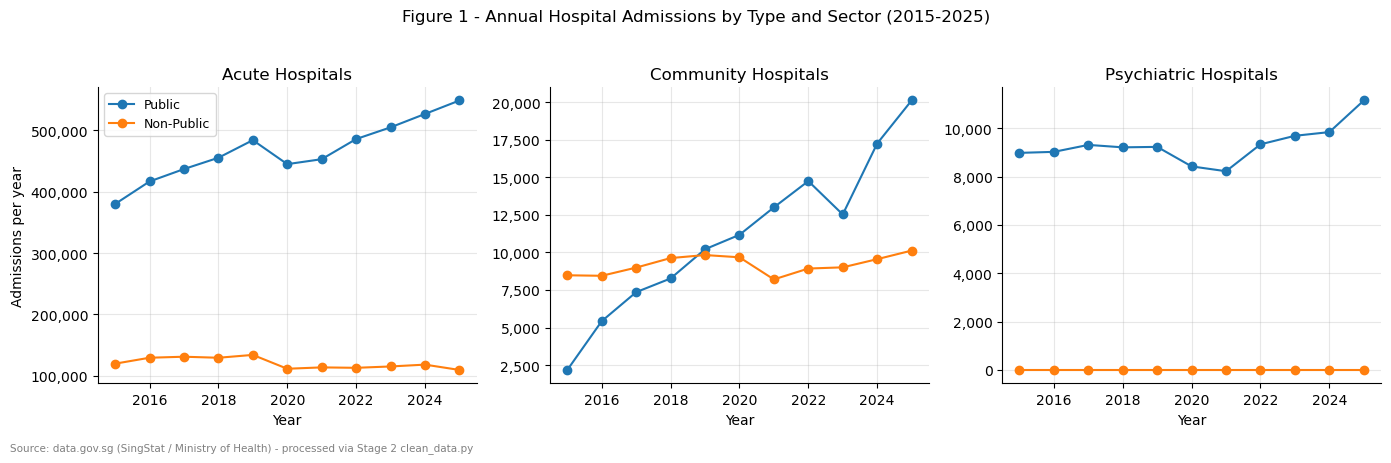

In [5]:
adm = monthly[monthly["measure_type"] == "Hospital Admissions"]
admissions_annual_sector = (
    adm.groupby(["year", "service_category", "sector"])["count"].sum().unstack("sector").fillna(0)
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True)
for ax, cat in zip(axes, ["Acute Hospitals", "Community Hospitals", "Psychiatric Hospitals"]):
    sub = admissions_annual_sector.xs(cat, level="service_category")
    for sector in ["Public", "Non-Public"]:
        if sector in sub.columns:
            ax.plot(sub.index, sub[sector], marker="o", label=sector, color=COLOR[sector])
    ax.set_title(cat)
    ax.set_xlabel("Year")
    comma_fmt(ax)
axes[0].set_ylabel("Admissions per year")
axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Figure 1 - Annual Hospital Admissions by Type and Sector (2015-2025)", y=1.03, fontsize=12)
add_source_note(fig)
plt.tight_layout()
plt.savefig(FIGURES / "fig01_admissions_by_sector.png", bbox_inches="tight")
plt.show()

**What this shows:** Acute Hospital admissions are overwhelmingly Public-sector and dominate total volume (~500,000-660,000/year), dwarfing Community (thousands) and Psychiatric (under 11,500) admissions on the same scale — note the very different y-axis ranges across panels. **Psychiatric Hospital admissions have zero Non-Public volume in every year**, consistent with the facilities dataset showing no Private/Not-for-Profit psychiatric hospital beds in Singapore over this period — this is a genuine structural feature of the sector, not a data gap. Community Hospital admissions grew the fastest in percentage terms of the three categories over 2015-2025. **Why it matters:** this is the core evidence for Business Question 1 (utilisation trends) and Question 3 context (sector mix of demand).

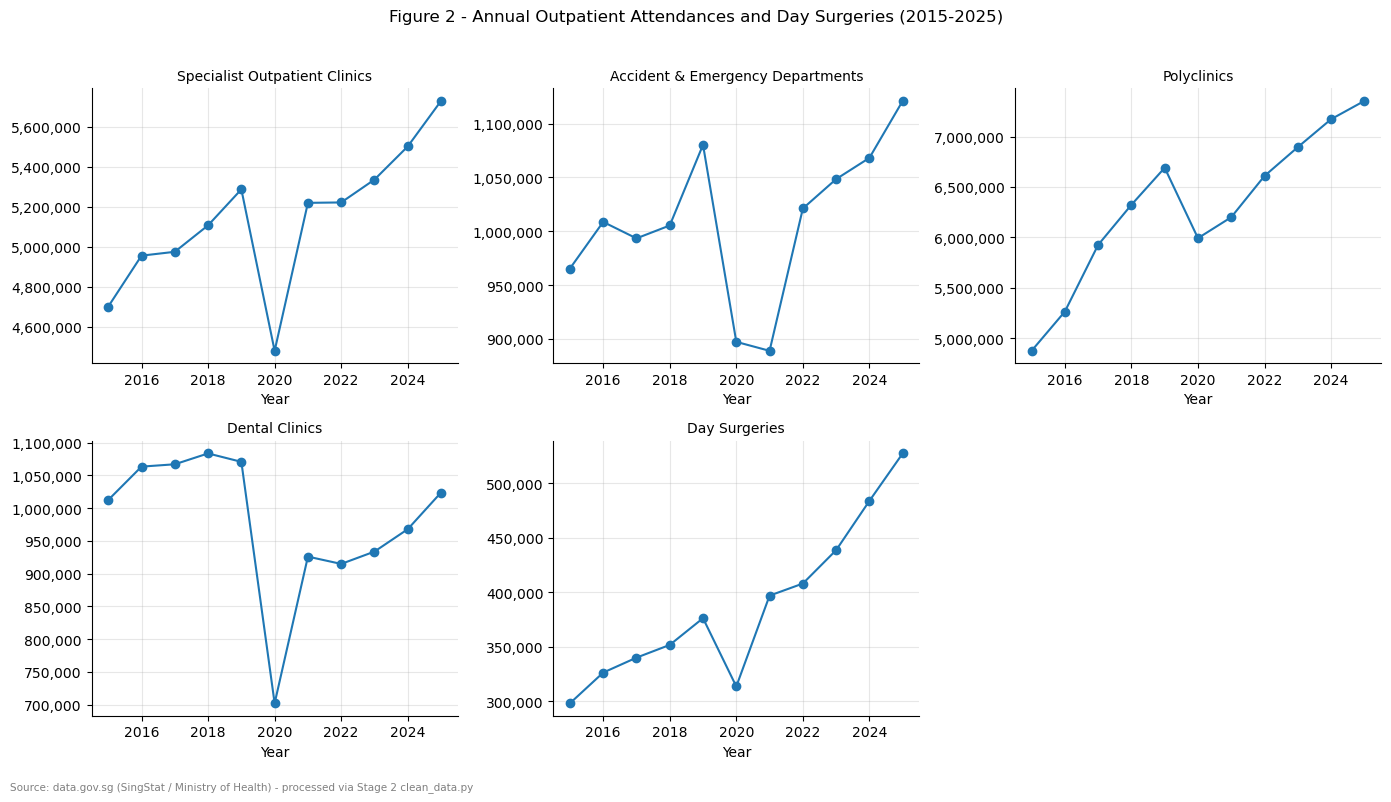

In [6]:
out = monthly[monthly["measure_type"] == "Outpatient Attendances"]
ds = monthly[monthly["measure_type"] == "Day Surgeries"]
outpatient_annual = out.groupby(["year", "service_category"])["count"].sum().unstack()
day_surgeries_annual = ds.groupby("year")["count"].sum()

panels = ["Specialist Outpatient Clinics", "Accident & Emergency Departments", "Polyclinics",
          "Dental Clinics", "Day Surgeries"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
axes = axes.flatten()
for ax, cat in zip(axes, panels):
    series = day_surgeries_annual if cat == "Day Surgeries" else outpatient_annual[cat]
    ax.plot(series.index, series.values, marker="o", color="#1f77b4")
    ax.set_title(cat, fontsize=10)
    ax.set_xlabel("Year")
    comma_fmt(ax)
axes[-1].axis("off")  # 6th panel unused (5 series)
fig.suptitle("Figure 2 - Annual Outpatient Attendances and Day Surgeries (2015-2025)", y=1.02, fontsize=12)
add_source_note(fig)
plt.tight_layout()
plt.savefig(FIGURES / "fig02_outpatient_small_multiples.png", bbox_inches="tight")
plt.show()

**What this shows:** each service is plotted on its own scale (small multiples) because magnitudes differ by more than 5x (Polyclinics ~7.4M/year vs. Dental Clinics ~1.0M/year). All five services shown here dipped in 2020, but the timing of recovery differed: Specialist Outpatient Clinics, Polyclinics, Dental Clinics and Day Surgeries had largely rebounded by 2021, while Accident & Emergency Departments continued to decline slightly in 2021 (-0.9%) and only rebounded in 2022 (+14.9%). The dip was sharpest for Dental Clinics. **Why it matters:** answers Business Question 2 (which services show the strongest growth) — Day Surgeries and Community Hospital admissions show the strongest sustained multi-year growth, while Dental Clinics shows the sharpest single-year disruption.

## 4. Seasonality and Year-over-Year Changes

Year-over-year (YoY) growth is calculated as `(current - previous) / previous * 100`, guarded against zero/undefined denominators (`np.where` with a `NaN` fallback; none of these series have a zero prior-year value, but the guard is kept for robustness). 2020-2022 is highlighted for context, **without assuming a causal mechanism** — the chart only describes the magnitude and timing of the change.

,Acute Hospital Admissions,Specialist Outpatient Clinics,Polyclinics,Dental Clinics,Day Surgeries
year,,,,,
2015,NaN,NaN,NaN,NaN,NaN
2016,9.3,5.4,8.0,5.0,9.5
2017,4.0,0.4,12.6,0.3,4.2
2018,2.9,2.7,6.7,1.6,3.4
2019,5.7,3.5,5.8,-1.2,7.0
2020,-10.0,-15.3,-10.4,-34.4,-16.7
2021,1.8,16.5,3.5,31.9,26.6
2022,5.7,0.0,6.6,-1.2,2.8
2023,3.6,2.2,4.3,2.1,7.5


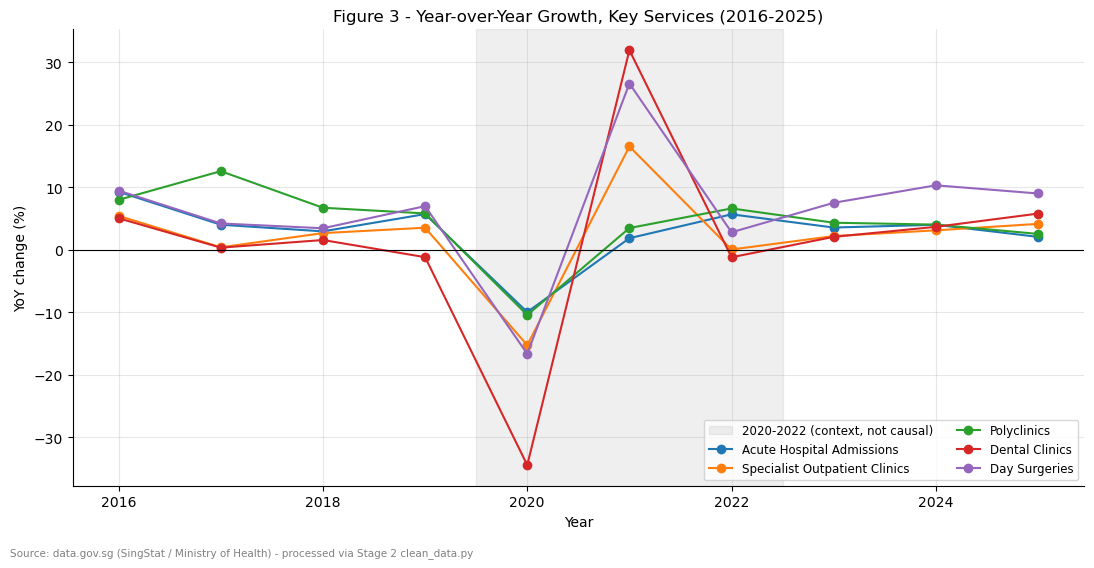

In [7]:
def yoy_pct(s):
    prev = s.shift(1)
    return pd.Series(np.where(prev == 0, np.nan, (s - prev) / prev * 100), index=s.index)

key_series = {
    "Acute Hospital Admissions": adm[adm.service_category == "Acute Hospitals"].groupby("year")["count"].sum(),
    "Specialist Outpatient Clinics": out[out.service_category == "Specialist Outpatient Clinics"].groupby("year")["count"].sum(),
    "Polyclinics": out[out.service_category == "Polyclinics"].groupby("year")["count"].sum(),
    "Dental Clinics": out[out.service_category == "Dental Clinics"].groupby("year")["count"].sum(),
    "Day Surgeries": day_surgeries_annual,
}
yoy_table = pd.DataFrame({name: yoy_pct(s) for name, s in key_series.items()})
display(yoy_table.round(1))

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.axvspan(2019.5, 2022.5, color="gray", alpha=0.12, label="2020-2022 (context, not causal)")
for name in yoy_table.columns:
    ax.plot(yoy_table.index, yoy_table[name], marker="o", label=name)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Figure 3 - Year-over-Year Growth, Key Services (2016-2025)")
ax.set_xlabel("Year")
ax.set_ylabel("YoY change (%)")
ax.legend(loc="lower right", fontsize=8.5, ncol=2)
add_source_note(fig)
plt.tight_layout()
plt.savefig(FIGURES / "fig03_yoy_growth.png", bbox_inches="tight")
plt.show()

In [8]:
# Broader check: does the 2020-contraction / 2021-rebound pattern in Figure 3
# hold across EVERY service category, or only the five selected there?
all_categories = {
    "Acute Hospitals (Admissions)": adm[adm.service_category == "Acute Hospitals"].groupby("year")["count"].sum(),
    "Community Hospitals (Admissions)": adm[adm.service_category == "Community Hospitals"].groupby("year")["count"].sum(),
    "Psychiatric Hospitals (Admissions)": adm[adm.service_category == "Psychiatric Hospitals"].groupby("year")["count"].sum(),
    "Specialist Outpatient Clinics": out[out.service_category == "Specialist Outpatient Clinics"].groupby("year")["count"].sum(),
    "Accident & Emergency Departments": out[out.service_category == "Accident & Emergency Departments"].groupby("year")["count"].sum(),
    "Polyclinics": out[out.service_category == "Polyclinics"].groupby("year")["count"].sum(),
    "Dental Clinics": out[out.service_category == "Dental Clinics"].groupby("year")["count"].sum(),
    "Day Surgeries": day_surgeries_annual,
}
all_yoy = pd.DataFrame({name: yoy_pct(s) for name, s in all_categories.items()}).round(1)
all_yoy.loc[[2020, 2021, 2022]].T

year,2020,2021,2022
Acute Hospitals (Admissions),-10.0,1.8,5.7
Community Hospitals (Admissions),4.0,1.7,11.7
Psychiatric Hospitals (Admissions),-8.8,-2.4,13.5
Specialist Outpatient Clinics,-15.3,16.5,0.0
Accident & Emergency Departments,-16.9,-0.9,14.9
Polyclinics,-10.4,3.5,6.6
Dental Clinics,-34.4,31.9,-1.2
Day Surgeries,-16.7,26.6,2.8


**What this shows:** the five services *selected for Figure 3* (Acute Hospital Admissions, Specialist Outpatient Clinics, Polyclinics, Dental Clinics, Day Surgeries) all contracted in 2020 (Dental Clinics most sharply, **-34.4%**; Specialist Outpatient Clinics **-15.3%**; Day Surgeries **-16.7%**; Acute Admissions **-10.0%**), followed by a rebound in 2021 (Dental Clinics **+31.9%**, Day Surgeries **+26.6%**).

**This pattern was not universal across every service category**, as the broader table above shows: **Community Hospital admissions grew in 2020 (+4.0%)** rather than contracting, and **Psychiatric Hospital admissions declined in *both* 2020 (-8.8%) and 2021 (-2.4%)** rather than rebounding. Accident & Emergency Departments (not one of the five plotted here) also kept declining through 2021 (-0.9%) before rebounding in 2022. **Why it matters:** this is descriptive evidence of an unusual 2020-2022 period, but its shape varied by service — the shaded band marks *when* a disruption was visible for the plotted services, not a claim that every service moved the same way, and not *why* it happened.

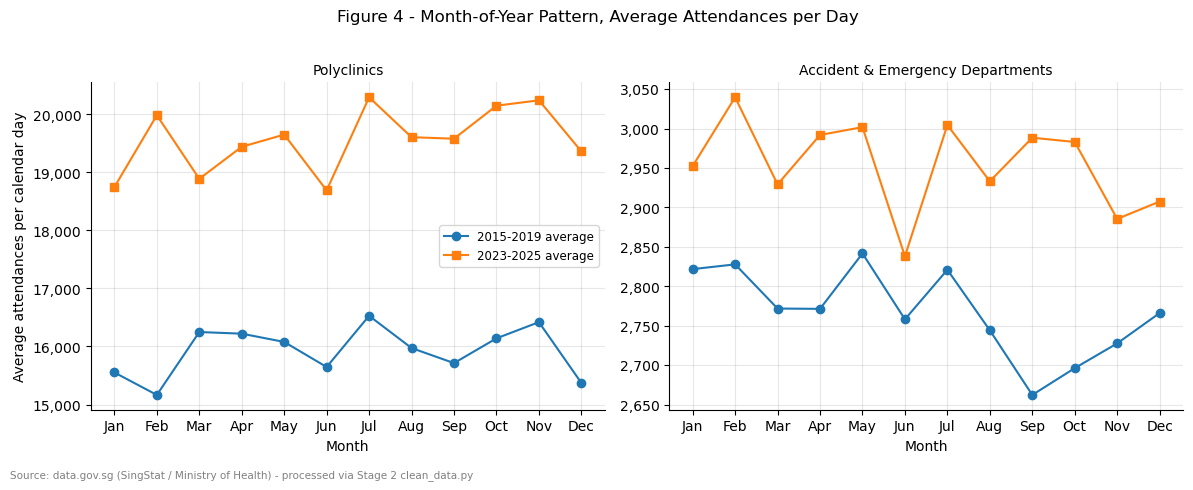

In [9]:
monthly["days_in_month"] = monthly["date"].dt.days_in_month
monthly["daily_avg"] = monthly["count"] / monthly["days_in_month"]
monthly["month_num"] = monthly["date"].dt.month

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)
for ax, cat in zip(axes, ["Polyclinics", "Accident & Emergency Departments"]):
    sub = monthly[monthly.service_category == cat]
    pre = sub[sub.year.between(2015, 2019)].groupby("month_num")["daily_avg"].mean()
    recent = sub[sub.year.between(2023, 2025)].groupby("month_num")["daily_avg"].mean()
    ax.plot(pre.index, pre.values, marker="o", label="2015-2019 average")
    ax.plot(recent.index, recent.values, marker="s", label="2023-2025 average")
    ax.set_title(cat, fontsize=10)
    ax.set_xlabel("Month")
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
    comma_fmt(ax)
axes[0].set_ylabel("Average attendances per calendar day")
axes[0].legend(fontsize=8.5)
fig.suptitle("Figure 4 - Month-of-Year Pattern, Average Attendances per Day", y=1.02, fontsize=12)
add_source_note(fig)
plt.tight_layout()
plt.savefig(FIGURES / "fig04_seasonality.png", bbox_inches="tight")
plt.show()

**What this shows:** counts are converted to an average-per-calendar-day basis so months of different lengths (28-31 days) are comparable. 2020-2022 (the unusual period identified above) is deliberately excluded from both averages so it does not distort the "typical" pattern. For both Polyclinics and A&E, month-to-month variation is modest (roughly a 6-9% range between the lowest and highest month) rather than a sharp, dominant seasonal cycle. **Caveat:** this is a *descriptive* month-of-year average, not a statistically tested seasonal decomposition (e.g. no STL/ACF significance testing) — read it as "a mild recurring pattern is visible," not as a validated seasonal model. **Why it matters:** answers Business Question 2 (seasonal patterns) with an honest level of confidence.

## 5. Hospital Capacity Trends

This section uses only `institution_type == "Hospital"` rows from the facilities dataset — Residential Long-Term Care (Nursing Homes, Inpatient Hospices) is excluded throughout, since it is a different category of care from acute/community/psychiatric hospital beds.

facility_type,Acute Hospitals,Community Hospitals,Psychiatric Hospitals
year,,,
2015,9844,1464,1950
2016,10318,1663,1950
2017,10340,1663,1950
2018,10826,1778,1950
2019,11321,1986,1950
2020,11545,2069,1950
2021,11704,2079,1950
2022,11830,2194,1950
2023,12025,2303,1950


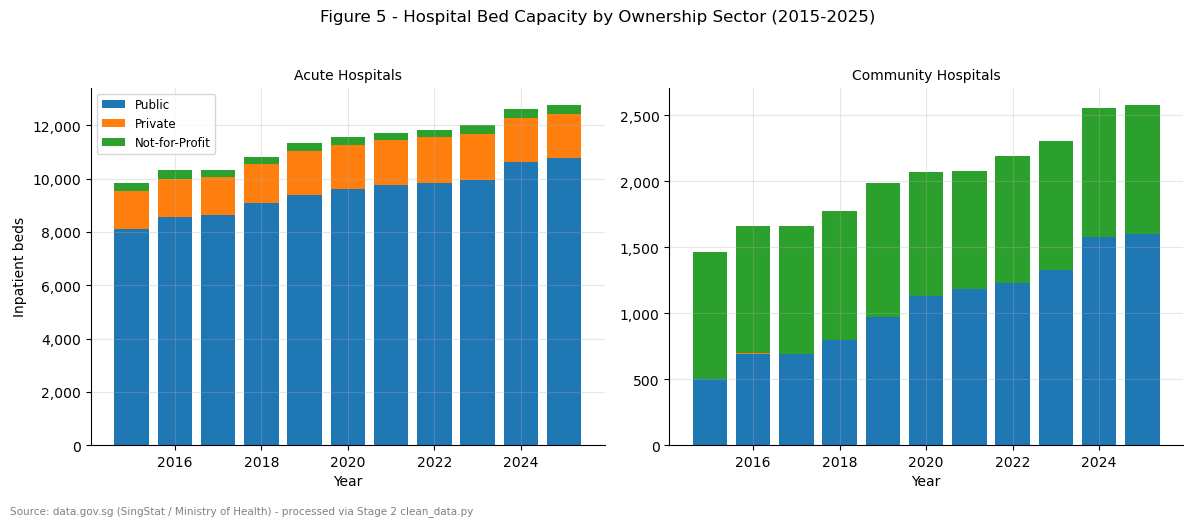

In [10]:
hosp = facilities[facilities.institution_type == "Hospital"]
beds_by_type = hosp.groupby(["year", "facility_type"])["no_beds"].sum().unstack()
display(beds_by_type)

acute_sector = hosp[hosp.facility_type == "Acute Hospitals"].groupby(["year", "sector"])["no_beds"].sum().unstack()
community_sector = hosp[hosp.facility_type == "Community Hospitals"].groupby(["year", "sector"])["no_beds"].sum().unstack()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, data, title in zip(axes, [acute_sector, community_sector], ["Acute Hospitals", "Community Hospitals"]):
    sector_order = [s for s in ["Public", "Private", "Not-for-Profit"] if s in data.columns]
    bottom = np.zeros(len(data))
    for sector in sector_order:
        ax.bar(data.index, data[sector], bottom=bottom, label=sector, color=COLOR.get(sector))
        bottom += data[sector].values
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Year")
    comma_fmt(ax)
axes[0].set_ylabel("Inpatient beds")
axes[0].legend(fontsize=8.5)
fig.suptitle("Figure 5 - Hospital Bed Capacity by Ownership Sector (2015-2025)", y=1.03, fontsize=12)
add_source_note(fig)
plt.tight_layout()
plt.savefig(FIGURES / "fig05_bed_composition.png", bbox_inches="tight")
plt.show()

**What this shows:** Public-sector beds dominate and have grown the most in absolute terms for both Acute Hospitals (8,128 → 10,784 beds, 2015-2025) and Community Hospitals. Private and Not-for-Profit bed counts are comparatively small and have grown much more slowly. Psychiatric Hospital beds are omitted from this chart because they are 100% Public and flat at 1,950 beds throughout — there is no sector composition to show. **Why it matters:** directly addresses Business Question 3 (capacity change by sector and facility type).

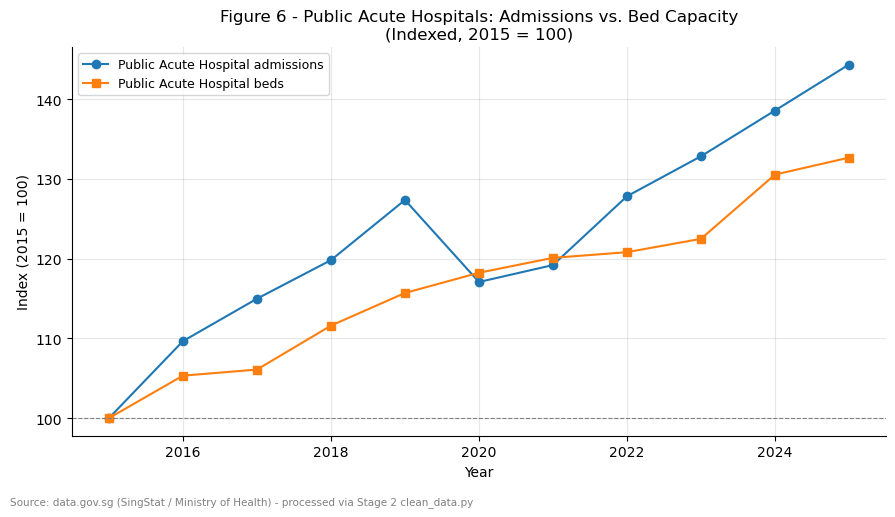

2025 vs 2015: admissions index = 144.4, beds index = 132.7


In [11]:
pub_acute_admissions = adm[(adm.service_category == "Acute Hospitals") & (adm.sector == "Public")].groupby("year")["count"].sum()
pub_acute_beds = hosp[(hosp.facility_type == "Acute Hospitals") & (hosp.sector == "Public")].groupby("year")["no_beds"].sum()

baseline_year = 2015
idx_admissions = pub_acute_admissions / pub_acute_admissions.loc[baseline_year] * 100
idx_beds = pub_acute_beds / pub_acute_beds.loc[baseline_year] * 100

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(idx_admissions.index, idx_admissions.values, marker="o", label="Public Acute Hospital admissions")
ax.plot(idx_beds.index, idx_beds.values, marker="s", label="Public Acute Hospital beds")
ax.axhline(100, color="gray", linewidth=0.8, linestyle="--")
ax.set_title(f"Figure 6 - Public Acute Hospitals: Admissions vs. Bed Capacity\n(Indexed, {baseline_year} = 100)")
ax.set_xlabel("Year")
ax.set_ylabel(f"Index ({baseline_year} = 100)")
ax.legend(fontsize=9)
add_source_note(fig)
plt.tight_layout()
plt.savefig(FIGURES / "fig06_admissions_vs_beds_indexed.png", bbox_inches="tight")
plt.show()

print(f"2025 vs {baseline_year}: admissions index = {idx_admissions.loc[2025]:.1f}, beds index = {idx_beds.loc[2025]:.1f}")

**What this shows:** both series are indexed to their own 2015 value (**baseline clearly = 100**) so growth *rates* can be compared on one scale despite very different absolute units (admission counts vs. bed counts). Public Acute Hospital admissions grew faster than Public Acute Hospital bed capacity over 2015-2025 (admissions index ≈144 vs. beds index ≈133 by 2025) — i.e. admissions volume grew at a faster relative rate than bed capacity over this decade. **This chart does not calculate, imply, or label an occupancy or utilisation rate** — admissions counted over a year and a point-in-time bed count are not divisible into a meaningful ratio, and no such ratio is computed anywhere in this notebook. **Why it matters:** directly addresses Business Question 4 (relative pace of admissions vs. capacity change).

## 6. Regional Bed Distribution

**Important framing:** the regional dataset describes where hospital beds are physically located, not where patients needing care live. No conclusion is drawn here about any region being "underserved" — that would require population, catchment-area or demand data not present in this project.

**2021 discrepancy restated:** when this dataset is summed for Community Hospitals / Public / 2021, it totals **1,112** beds, while the national facilities dataset reports **1,180** for the same combination — a 68-bed gap. The chart below uses the regional dataset's own figures as published; it is not adjusted to match the national total.

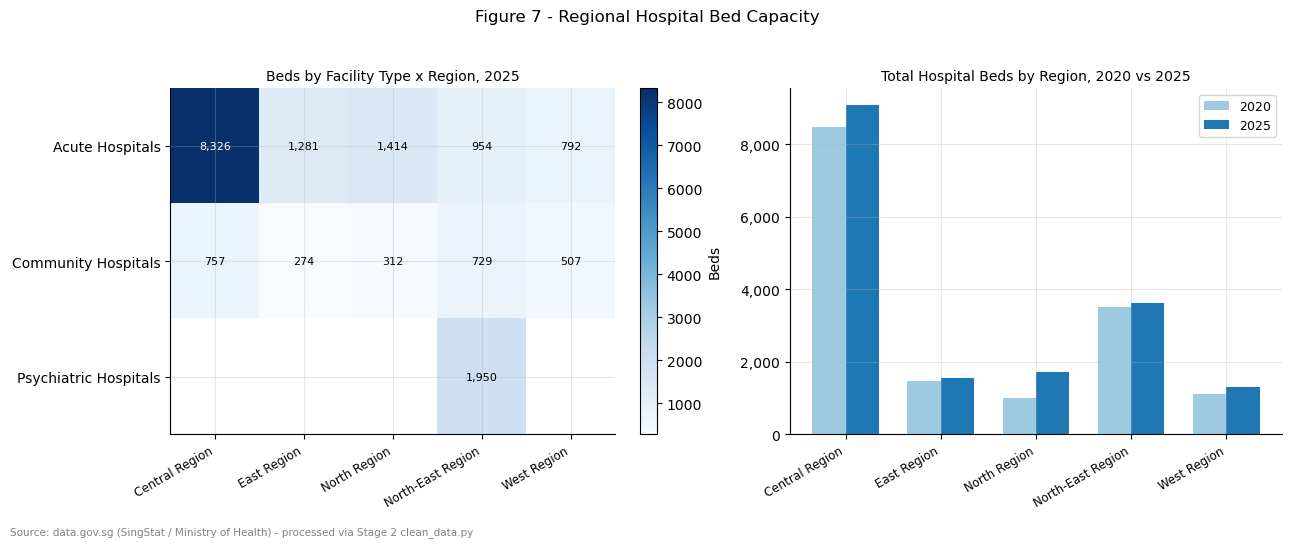

2025 share of total hospital beds by region (%):
planning_region
Central Region       52.5
East Region           9.0
North Region         10.0
North-East Region    21.0
West Region           7.5
Name: no_beds, dtype: float64


In [12]:
region_order = ["Central Region", "East Region", "North Region", "North-East Region", "West Region"]
pivot_2025 = (regional[regional.year == 2025]
              .groupby(["facility_type", "planning_region"])["no_beds"].sum()
              .unstack().reindex(columns=region_order))
region_totals = regional.groupby(["year", "planning_region"])["no_beds"].sum().unstack().reindex(columns=region_order)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im = axes[0].imshow(pivot_2025.values, cmap="Blues", aspect="auto")
axes[0].set_xticks(range(len(region_order)))
axes[0].set_xticklabels(region_order, rotation=30, ha="right", fontsize=8.5)
axes[0].set_yticks(range(len(pivot_2025.index)))
axes[0].set_yticklabels(pivot_2025.index)
axes[0].set_title("Beds by Facility Type x Region, 2025", fontsize=10)
for i in range(pivot_2025.shape[0]):
    for j in range(pivot_2025.shape[1]):
        val = pivot_2025.values[i, j]
        if not np.isnan(val):
            axes[0].text(j, i, f"{val:,.0f}", ha="center", va="center", fontsize=8,
                         color="white" if val > np.nanmax(pivot_2025.values) * 0.5 else "black")
fig.colorbar(im, ax=axes[0], label="Beds", fraction=0.046)

x = np.arange(len(region_order))
width = 0.35
axes[1].bar(x - width/2, region_totals.loc[2020].values, width, label="2020", color="#9ecae1")
axes[1].bar(x + width/2, region_totals.loc[2025].values, width, label="2025", color="#1f77b4")
axes[1].set_xticks(x)
axes[1].set_xticklabels(region_order, rotation=30, ha="right", fontsize=8.5)
axes[1].set_title("Total Hospital Beds by Region, 2020 vs 2025", fontsize=10)
comma_fmt(axes[1])
axes[1].legend(fontsize=9)

fig.suptitle("Figure 7 - Regional Hospital Bed Capacity", y=1.03, fontsize=12)
add_source_note(fig)
plt.tight_layout()
plt.savefig(FIGURES / "fig07_regional_capacity.png", bbox_inches="tight")
plt.show()

share_2025 = (regional[regional.year == 2025].groupby("planning_region")["no_beds"].sum()
              .reindex(region_order))
print("2025 share of total hospital beds by region (%):")
print((share_2025 / share_2025.sum() * 100).round(1))

**What this shows:** the Central Region holds the largest share of hospital beds (**≈52.5% of the 2025 total**), consistent with the concentration of Acute Hospital capacity there, followed by the North-East Region (**≈21.0%**). The remaining three regions each hold a smaller, broadly similar share: East **≈9.0%**, North **≈10.0%** and West **≈7.5%**. All regions grew in absolute bed count between 2020 and 2025 (Central Region: 8,466 → 9,083). Psychiatric Hospital beds are entirely concentrated in the North-East Region (the only region with any psychiatric hospital rows at all) — the blank heatmap cells for Psychiatric Hospitals elsewhere are a genuine absence of capacity there, not missing data. **Why it matters:** directly addresses Business Question 5. **Limitation:** this describes supply-side facility location only; it says nothing about whether capacity matches regional population or demand.

## 7. Key Findings and Limitations

See `STAGE3_EDA_FINDINGS.md` for the full write-up with supporting figures. In summary:

1. **Acute Hospital admissions remain Public-dominated and the largest volume category** (~658,000 in 2025), growing ~32% over 2015-2025 while Community Hospital admissions grew faster in relative terms (~183%, off a much smaller base).
2. **The five services selected for Figure 3 all contracted in 2020 and rebounded in 2021**, most sharply for Dental Clinics (-34.4% then +31.9%) — described, not causally explained. **This was not universal**: Community Hospital admissions grew in 2020 (+4.0%) instead of contracting, and Psychiatric Hospital admissions declined in both 2020 and 2021 (-8.8%, -2.4%) instead of rebounding.
3. **Public Acute Hospital admissions grew faster than Public Acute Hospital bed capacity** over 2015-2025 (admissions index ≈144 vs. beds index ≈133, 2015=100) — a capacity-growth gap, not an occupancy rate.
4. **Hospital bed capacity is heavily concentrated in the Central Region** (≈52.5% of 2025 beds), followed by the North-East Region (≈21.0%); the remaining three regions (East, North, West) each hold roughly 7.5%-10.0%. Psychiatric Hospital beds are located exclusively in the North-East Region.
5. **A genuine, unresolved 68-bed discrepancy exists for 2021 Public Community Hospital beds** between the national (1,180) and regional (1,112) datasets — both values are retained unmodified and should be treated as a known limitation in any 2021 Community Hospital analysis.

**Analytical limitations carried into Stage 4:**
- No common join key across the three datasets; all comparisons here are by shared dimensions (year, facility type, sector), not row-level joins.
- Non-Public admissions (Dataset 1) are not assumed equivalent to Private/Not-for-Profit beds (Datasets 2-3) without further source-definition confirmation.
- No occupancy, utilisation-rate, forecasting or statistical-significance analysis was performed.
- Regional data covers 2020-2025 only; national/monthly data covers more years but cannot be broken down regionally.